# ЕМП: маршрут на дрона с ограничение на батерията
**Тема 2 – Дрон инспектор на сгради** · част по „Евристични методи за прогнозиране“

**Задача.** От АСД частта имаме n зони с пукнатини – център и площ на всяка. Дронът трябва да огледа всички зони отблизо. Батерията стига за ограничено разстояние, затова полетът се разделя на **рейсове**: база → няколко зони → база (смяна на батерията) → …

**Цел:** минимално общо изминато разстояние.

**Сравняваме:**
| Метод | Тип | Сложност |
|---|---|---|
| Най-близък съсед (с проверка на батерията) | евристика, алчна | O(n²) |
| Генетичен алгоритъм | евристика, популационна | O(поколения · популация · n·L) |
| Пълно изчерпване + оптимално разделяне | **точно решение** | O(n! · n²) – само при n ≤ 8 |

In [1]:
# Настройка: в Colab клонираме хранилището, локално ползваме папката src/
import os, sys
REPO_URL = "https://github.com/<потребител>/nm-cnn-dron-<екип>.git"  # ← сменете с адреса на вашето хранилище
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/repo"):
        !git clone -q $REPO_URL /content/repo
    os.chdir("/content/repo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Работна папка:", os.getcwd())

Работна папка: /home/user/drone-crack-inspector


In [2]:
import inspect
from IPython.display import Code, display

def show(obj):
    """Показва изходния код на функция от src/ – кодът е на едно място, тук само го четем."""
    display(Code(inspect.getsource(obj), language="python"))
import math, time, random, statistics
import numpy as np
import matplotlib.pyplot as plt
from src.route_planning import (RoutingProblem, distance_matrix, nearest_neighbor, genetic_algorithm,
                                exact_solution, split_tour, random_problem, is_feasible,
                                trip_energy, _order_crossover, _mutate)
from src.viz import plot_route

## 1. Математически модел
* Точка 0 е **базата**, точки 1..n са центровете на зоните; $d_{ij}$ – евклидово разстояние в метри (в равнината на стената).
* Огледът на зона i струва $s_i$ единици енергия (пропорционално на площта ѝ).
* Батерия: $B$ единици енергия (1 единица ≈ 1 m полет).
* Рейс $T = (i_1, \dots, i_m)$ е **допустим**, ако
$$E(T) = d_{0 i_1} + \sum_{k=1}^{m-1} d_{i_k i_{k+1}} + d_{i_m 0} + \sum_{k} s_{i_k} \le B$$
* Търсим рейсове $T_1, \dots, T_r$, които покриват всяка зона точно веднъж и минимизират $\sum_j \text{разстояние}(T_j)$.

При $B = \infty$ това е точно **задачата за пътуващия търговец** → задачата е NP-трудна и при много зони точното решение е непрактично.

**Допускания на учебния модел:** дронът лети по права (без препятствия), скоростта и разходът са постоянни, вятър няма, смяната на батерията е мигновена.

## 2. Матрица на разстоянията

In [3]:
p = random_problem(6, seed=1)
D = np.array(p.dist)
print("Батерия B =", round(p.battery, 1), "| енергия за оглед s =", [round(s, 1) for s in p.service])
print("Матрица на разстоянията (m), ред/колона 0 = база:")
print(np.round(D, 1))

Батерия B = 92.0 | енергия за оглед s = [0.0, 4.8, 1.0, 3.2, 4.6, 2.1, 5.7]
Матрица на разстоянията (m), ред/колона 0 = база:
[[ 0.  13.3 23.2 16.3 22.8  2.8 25.9]
 [13.3  0.  20.9 12.4 15.5 12.3 21.9]
 [23.2 20.9  0.   8.6  8.7 20.4  3.4]
 [16.3 12.4  8.6  0.   6.9 13.6 10.2]
 [22.8 15.5  8.7  6.9  0.  20.2  7.7]
 [ 2.8 12.3 20.4 13.6 20.2  0.  23.1]
 [25.9 21.9  3.4 10.2  7.7 23.1  0. ]]


## 3. Евристика 1: най-близък съсед
От текущата позиция летим до **най-близката неогледана зона, след която батерията стига за връщане в базата**. Ако за нито една зона не стига – връщаме се, сменяме батерията и започваме нов рейс.

* Плюсове: много бърза (O(n²)), проста, винаги дава допустимо решение.
* Минуси: „късогледа“ – в края на рейса често остават далечни зони, до които се лети на зиг-заг; няма поглед напред.

In [4]:
show(nearest_neighbor)

def nearest_neighbor(problem: RoutingProblem) -> RouteResult:
    """От текущата позиция летим до най-близката неогледана зона, ако след
    нея батерията стига, за да се върнем в базата. Ако за нито една зона не
    стига – връщаме се, сменяме батерията и започваме нов рейс.

    Сложност: O(n²) – n избора, всеки преглежда до n кандидата.
    """
    t0 = time.perf_counter()
    d, s, B = problem.dist, problem.service, problem.battery
    unvisited = set(range(1, problem.n + 1))
    trips: Trips = []
    while unvisited:
        cur, left, trip = 0, B, []
        while True:
            best, best_d = None, float("inf")
            for j in unvisited:
                can_return = d[cur][j] + s[j] + d[j][0] <= left + 1e-9
                if can_return and (d[cur][j] < best_d or (d[cur][j] == best_d and j < best)):
                    best, best_d = j, d[cur][j]
            if best is None:
                break
            left -= d[cur][best] + s[best]
            trip.append(best)
            unvisited.remove(best)
            cur = best
        trips.append(trip)  # винаги поне 1 зона – всяка зона е достижима сама
    return RouteResult("Най-близък съсед", trips, total_distance(problem, trips),
                       time.perf_counter() - t0)

## 4. Евристика 2: генетичен алгоритъм
| Елемент | Избор | Защо |
|---|---|---|
| Хромозома | пермутация на зоните (ред на облитане) | всяка пермутация е валидна – няма „невъзможни“ индивиди |
| Декодиране | `split_tour`: оптимално разделяне на пермутацията на рейсове (динамично програмиране O(n²)) | батерията се спазва автоматично |
| Приспособимост | общо разстояние (по-малко = по-добре) | |
| Селекция | турнир от 3 | прост контрол на натиска на селекцията |
| Кръстосване | OX (order crossover), p = 0.9 | запазва относителния ред на гените → резултатът е пермутация |
| Мутация | обръщане на отрязък (70 %) или размяна (30 %), p = 0.3 | обръщането „разплита“ кръстосани отсечки (като 2-opt) |
| Елитизъм | 2 най-добри преминават без промяна | най-доброто не се губи |
| Спиране | 400 поколения или 120 без подобрение | |

In [5]:
show(split_tour)
show(_order_crossover)
show(genetic_algorithm)

def split_tour(problem: RoutingProblem, order: Sequence[int]) -> Tuple[float, Trips]:
    """При ЗАДАДЕН ред на зоните намира най-доброто им разделяне на рейсове.

    V[j] = минимално разстояние, за да се огледат първите j зони от реда.
    V[j+1] = min_i ( V[i] + разстояние на рейса order[i..j] ), ако рейсът
    се побира в батерията. Сложност O(n²) (на практика O(n·L), L – брой
    зони в един рейс, защото вътрешният цикъл спира при изтощена батерия).
    Използва се като "декодер" в генетичния алгоритъм и в точния метод.
    """
    d, s, B = problem.dist, problem.service, problem.battery
    n = len(order)
    INF = float("inf")
    V = [0.0] + [INF] * n
    pred = [0] * (n + 1)
    for i in range(n):
        if V[i] == INF:
            continue
        energy = 0.0
        travel = 0.0
        for j in range(i, n):
            cur = order[j]
            if j == i:
                travel = d[0][cur]
            else:
                travel += d[order[j - 1]][cur]
            energy += s[cur]
            if travel + energy + d[cur][0] > B + 1e-9:
                break
            cost = travel + d[cur][0]
            if V[i] + cost < V[j + 1]:
                V[j + 1] = V[i] + cost
                pred[j + 1] = i
    trips: Trips = []
    j = n
    while j > 0:
        i = pred[j]
        trips.append(list(order[i:j]))
        j = i
    trips.reverse()
    return V[n], trips

def _order_crossover(p1: List[int], p2: List[int], rng: random.Random) -> List[int]:
    """Кръстосване с подредба (OX): копираме отрязък от p1, останалите гени
    добавяме в реда, в който се срещат в p2. Резултатът винаги е пермутация."""
    n = len(p1)
    a, b = sorted(rng.sample(range(n), 2))
    child: List[Optional[int]] = [None] * n
    child[a:b + 1] = p1[a:b + 1]
    taken = set(p1[a:b + 1])
    fill = [g for g in p2 if g not in taken]
    k = 0
    for i in range(n):
        if child[i] is None:
            child[i] = fill[k]
            k += 1
    return child  # type: ignore[return-value]

def genetic_algorithm(
    problem: RoutingProblem,
    pop_size: int = 80,
    generations: int = 400,
    crossover_rate: float = 0.9,
    mutation_rate: float = 0.3,
    tournament_k: int = 3,
    elite: int = 2,
    patience: int = 120,
    seed: Optional[int] = 0,
    initial: Optional[List[List[int]]] = None,
) -> RouteResult:
    """Генетичен алгоритъм.

    Хромозома: пермутация на зоните 1..n (ред на облитане).
    Декодиране: split_tour разделя пермутацията на рейсове по батерията.
    Приспособимост: общото разстояние (по-малко = по-добре).
    Оператори: турнирна селекция, кръстосване OX, мутация обръщане/размяна,
    елитизъм (най-добрите `elite` преминават без промяна).
    Спиране: `generations` поколения или `patience` поколения без подобрение.
    """
    t0 = time.perf_counter()
    rng = random.Random(seed)
    n = problem.n
    genes = list(range(1, n + 1))
    if n <= 2:  # тривиален случай – пробваме всички пермутации
        best = min((split_tour(problem, list(p)) for p in itertools.permutations(genes)),
                   key=lambda x: x[0])
        return RouteResult("Генетичен алгоритъм", best[1], best[0], time.perf_counter() - t0, [best[0]])

    cache: Dict[Tuple[int, ...], float] = {}

    def fitness(ind: List[int]) -> float:
        key = tuple(ind)
        if key not in cache:
            cache[key] = split_tour(problem, ind)[0]
        return cache[key]

    population = [list(p) for p in (initial or [])][:pop_size]
    while len(population) < pop_size:
        ind = genes[:]
        rng.shuffle(ind)
        population.append(ind)

    def tournament() -> List[int]:
        return min(rng.sample(population, tournament_k), key=fitness)

    best = min(population, key=fitness)
    best_cost = fitness(best)
    history = [best_cost]
    stale = 0
    for _ in range(generations):
        population.sort(key=fitness)
        new_pop = [ind[:] for ind in population[:elite]]
        while len(new_pop) < pop_size:
            p1, p2 = tournament(), tournament()
            child = _order_crossover(p1, p2, rng) if rng.random() < crossover_rate else p1[:]
            if rng.random() < mutation_rate:
                _mutate(child, rng)
            new_pop.append(child)
        population = new_pop
        gen_best = min(population, key=fitness)
        if fitness(gen_best) < best_cost - 1e-9:
            best, best_cost, stale = gen_best[:], fitness(gen_best), 0
        else:
            stale += 1
        history.append(best_cost)
        if stale >= patience:
            break
    cost, trips = split_tour(problem, best)
    return RouteResult("Генетичен алгоритъм", trips, cost, time.perf_counter() - t0, history)

## 5. Точно решение
Всяко допустимо решение (набор рейсове) е разделяне на някаква пермутация – тази, получена като залепим рейсовете един след друг. `split_tour` намира **най-доброто** разделяне на всяка пермутация. Следователно минимумът по всички n! пермутации е глобалният оптимум.

Сложност O(n! · n²): при n = 8 това са 40 320 пермутации (< 1 s), при n = 12 – 479 милиона (часове). Затова точното решение е само за малко зони.

In [6]:
show(exact_solution)

def exact_solution(problem: RoutingProblem, max_n: int = 9) -> RouteResult:
    """Пълно изчерпване: всички n! пермутации, всяка разделена оптимално.

    Защо е точно: всяко допустимо решение (набор от рейсове) е разделяне на
    някаква пермутация – тази, получена при залепване на рейсовете един след
    друг. split_tour намира НАЙ-ДОБРОТО разделяне на всяка пермутация, значи
    минимумът по всички пермутации е глобалният оптимум.
    Сложност: O(n! · n²) -> само при n <= max_n.
    """
    n = problem.n
    if n > max_n:
        raise ValueError(f"Точното решение е твърде бавно за n = {n} > {max_n}")
    t0 = time.perf_counter()
    best_cost, best_trips = float("inf"), []
    for perm in itertools.permutations(range(1, n + 1)):
        # Рейс и обратният му имат еднаква дължина (симетрични разстояния), но
        # пермутациите не са симетрични заради разделянето – затова обхождаме всички.
        cost, trips = split_tour(problem, perm)
        if cost < best_cost - 1e-12:
            best_cost, best_trips = cost, trips
    return RouteResult("Точно (изчерпване)", best_trips, best_cost, time.perf_counter() - t0)

Най-близък съсед         68.82 m  рейсове: [[5, 1, 3, 4, 6, 2]]  (0.0 ms)
Генетичен алгоритъм      65.00 m  рейсове: [[1, 4, 6, 2, 3, 5]]  (62.7 ms)
Точно (изчерпване)       65.00 m  рейсове: [[1, 4, 6, 2, 3, 5]]  (3.2 ms)


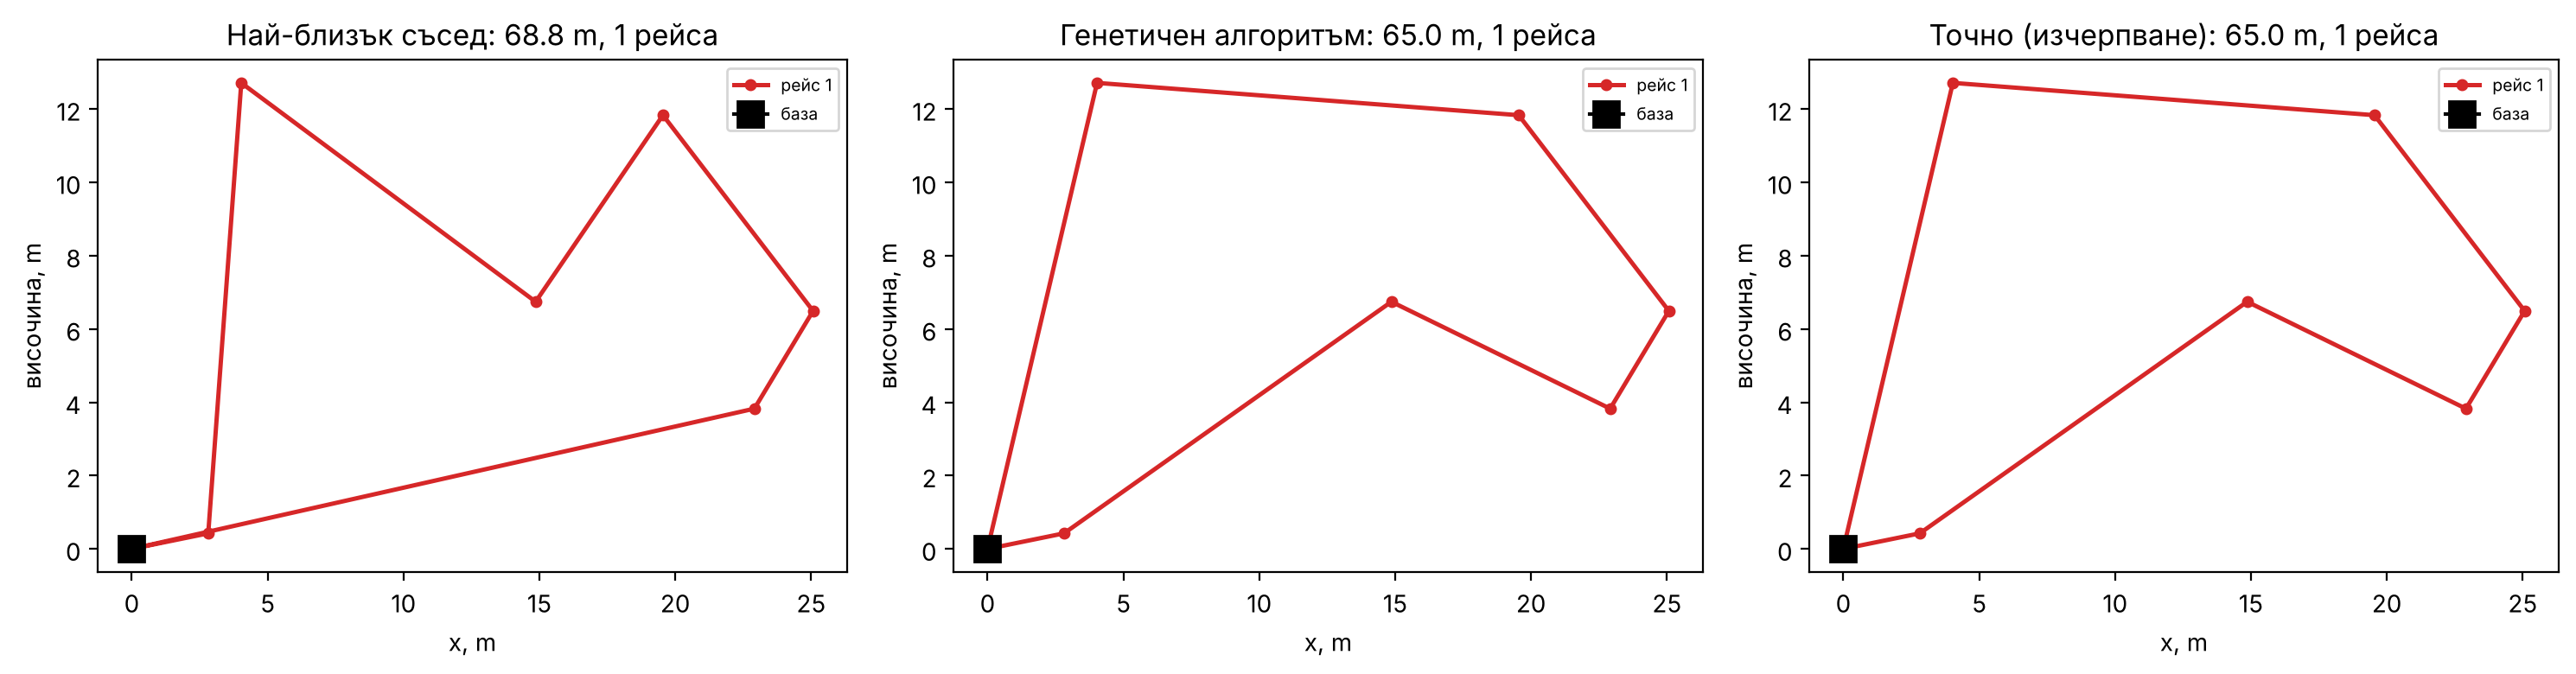

In [7]:
nn, ga, ex = nearest_neighbor(p), genetic_algorithm(p, seed=0), exact_solution(p)
for r in (nn, ga, ex):
    assert is_feasible(p, r.trips)
    print(f"{r.method:<22} {r.distance:7.2f} m  рейсове: {r.trips}  ({r.seconds*1000:.1f} ms)")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, r in zip(axes, (nn, ga, ex)):
    plot_route(p, r, ax=ax)
plt.tight_layout(); plt.show()

## 6. Експеримент 1: сравнение с точното решение (n = 4…8)
За всяко n генерираме 20 случайни задачи. Мерим:
* **отклонение от оптимума** = (разстояние − оптимум) / оптимум · 100 %;
* **% оптимално решени** задачи;
* **време**.

In [8]:
rows = []
for n in range(4, 9):
    for seed in range(20):
        prob = random_problem(n, seed=1000 * n + seed)
        ex = exact_solution(prob)
        for r in (nearest_neighbor(prob), genetic_algorithm(prob, seed=seed)):
            rows.append(dict(n=n, method=r.method, gap=max(0.0, (r.distance - ex.distance) / ex.distance * 100),
                             opt=math.isclose(r.distance, ex.distance, rel_tol=1e-9), ms=r.seconds * 1000))
        rows.append(dict(n=n, method=ex.method, gap=0.0, opt=True, ms=ex.seconds * 1000))

methods = ["Най-близък съсед", "Генетичен алгоритъм", "Точно (изчерпване)"]
print(f"{'n':>2} | {'метод':<22} | {'ср. откл. %':>11} | {'макс. откл. %':>13} | {'% оптимални':>11} | {'ср. време ms':>12}")
summary = {}
for n in range(4, 9):
    for m in methods:
        sel = [r for r in rows if r["n"] == n and r["method"] == m]
        g = [r["gap"] for r in sel]; t = [r["ms"] for r in sel]
        summary[(n, m)] = (statistics.mean(g), statistics.mean(t))
        print(f"{n:>2} | {m:<22} | {statistics.mean(g):11.2f} | {max(g):13.2f} | "
              f"{100 * sum(r['opt'] for r in sel) / len(sel):11.0f} | {statistics.mean(t):12.2f}")

 n | метод                  | ср. откл. % | макс. откл. % | % оптимални | ср. време ms
 4 | Най-близък съсед       |       12.94 |         75.30 |          20 |         0.01
 4 | Генетичен алгоритъм    |        0.00 |          0.00 |         100 |        48.99
 4 | Точно (изчерпване)     |        0.00 |          0.00 |         100 |         0.07
 5 | Най-близък съсед       |        5.88 |         42.98 |          30 |         0.01
 5 | Генетичен алгоритъм    |        0.00 |          0.00 |         100 |        52.43
 5 | Точно (изчерпване)     |        0.00 |          0.00 |         100 |         0.41
 6 | Най-близък съсед       |       25.80 |         90.18 |           5 |         0.02
 6 | Генетичен алгоритъм    |        0.00 |          0.00 |         100 |        53.16
 6 | Точно (изчерпване)     |        0.00 |          0.00 |         100 |         2.97
 7 | Най-близък съсед       |       26.05 |         76.72 |          15 |         0.02
 7 | Генетичен алгоритъм    |        0.00 |

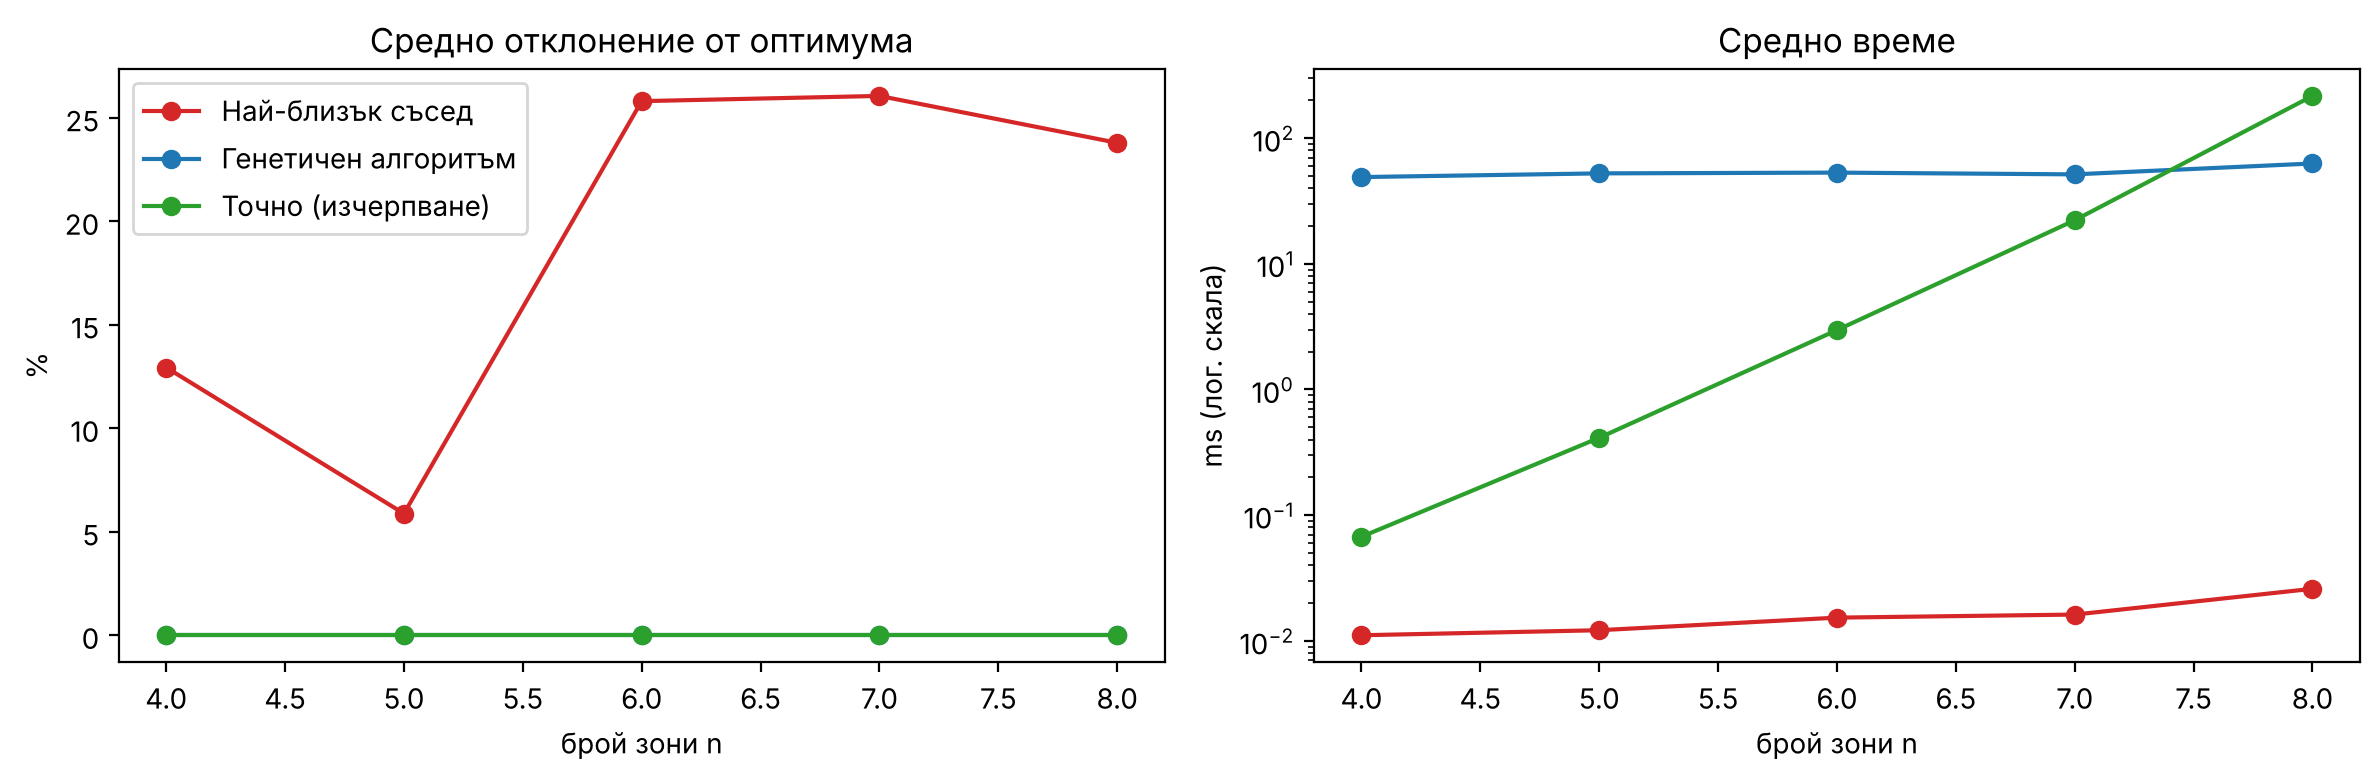

In [9]:
ns = list(range(4, 9))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, c in zip(methods, ["tab:red", "tab:blue", "tab:green"]):
    ax[0].plot(ns, [summary[(n, m)][0] for n in ns], "o-", color=c, label=m)
    ax[1].plot(ns, [summary[(n, m)][1] for n in ns], "o-", color=c, label=m)
ax[0].set_title("Средно отклонение от оптимума"); ax[0].set_ylabel("%"); ax[0].set_xlabel("брой зони n")
ax[1].set_title("Средно време"); ax[1].set_ylabel("ms (лог. скала)"); ax[1].set_yscale("log"); ax[1].set_xlabel("брой зони n")
ax[0].legend(); plt.tight_layout(); plt.savefig("results/emp_vs_exact.png", dpi=120); plt.show()

**Наблюдение (100 случайни задачи, n = 4…8):**
* Генетичният алгоритъм намира **оптимума във всички 100 задачи**.
* Най-близкият съсед е оптимален само в 5–30 % от задачите; средното отклонение е 6–26 %, а в най-лошите случаи маршрутът е почти **двойно по-дълъг**.
* Времето на точния метод расте като n! – наклонът в логаритмична скала: всяка +1 зона умножава времето ≈ по n. При n ≤ 7 точният метод е дори по-бърз от ГА (ГА има постоянна „цена“ от ~50 ms за поколенията), но при n = 8 вече е 4 пъти по-бавен, а при n = 12 би отнел часове.

## 7. Експеримент 2: много зони (n = 10…60) – само евристики
Тук точното решение е непрактично. Сравняваме двете евристики помежду им: колко процента по-къс е маршрутът на ГА от този на най-близкия съсед и колко време струва това.

n = 10: НС   126.9 m (  0.02 ms) | ГА    92.4 m (     96 ms) | ГА по-къс с 26.2 %


n = 20: НС   168.9 m (  0.05 ms) | ГА   141.8 m (    253 ms) | ГА по-къс с 13.2 %


n = 30: НС   226.3 m (  0.09 ms) | ГА   184.5 m (    563 ms) | ГА по-къс с 17.1 %


n = 40: НС   255.0 m (  0.11 ms) | ГА   222.9 m (    903 ms) | ГА по-къс с 12.4 %


n = 60: НС   353.6 m (  0.23 ms) | ГА   311.8 m (   1726 ms) | ГА по-къс с 11.4 %


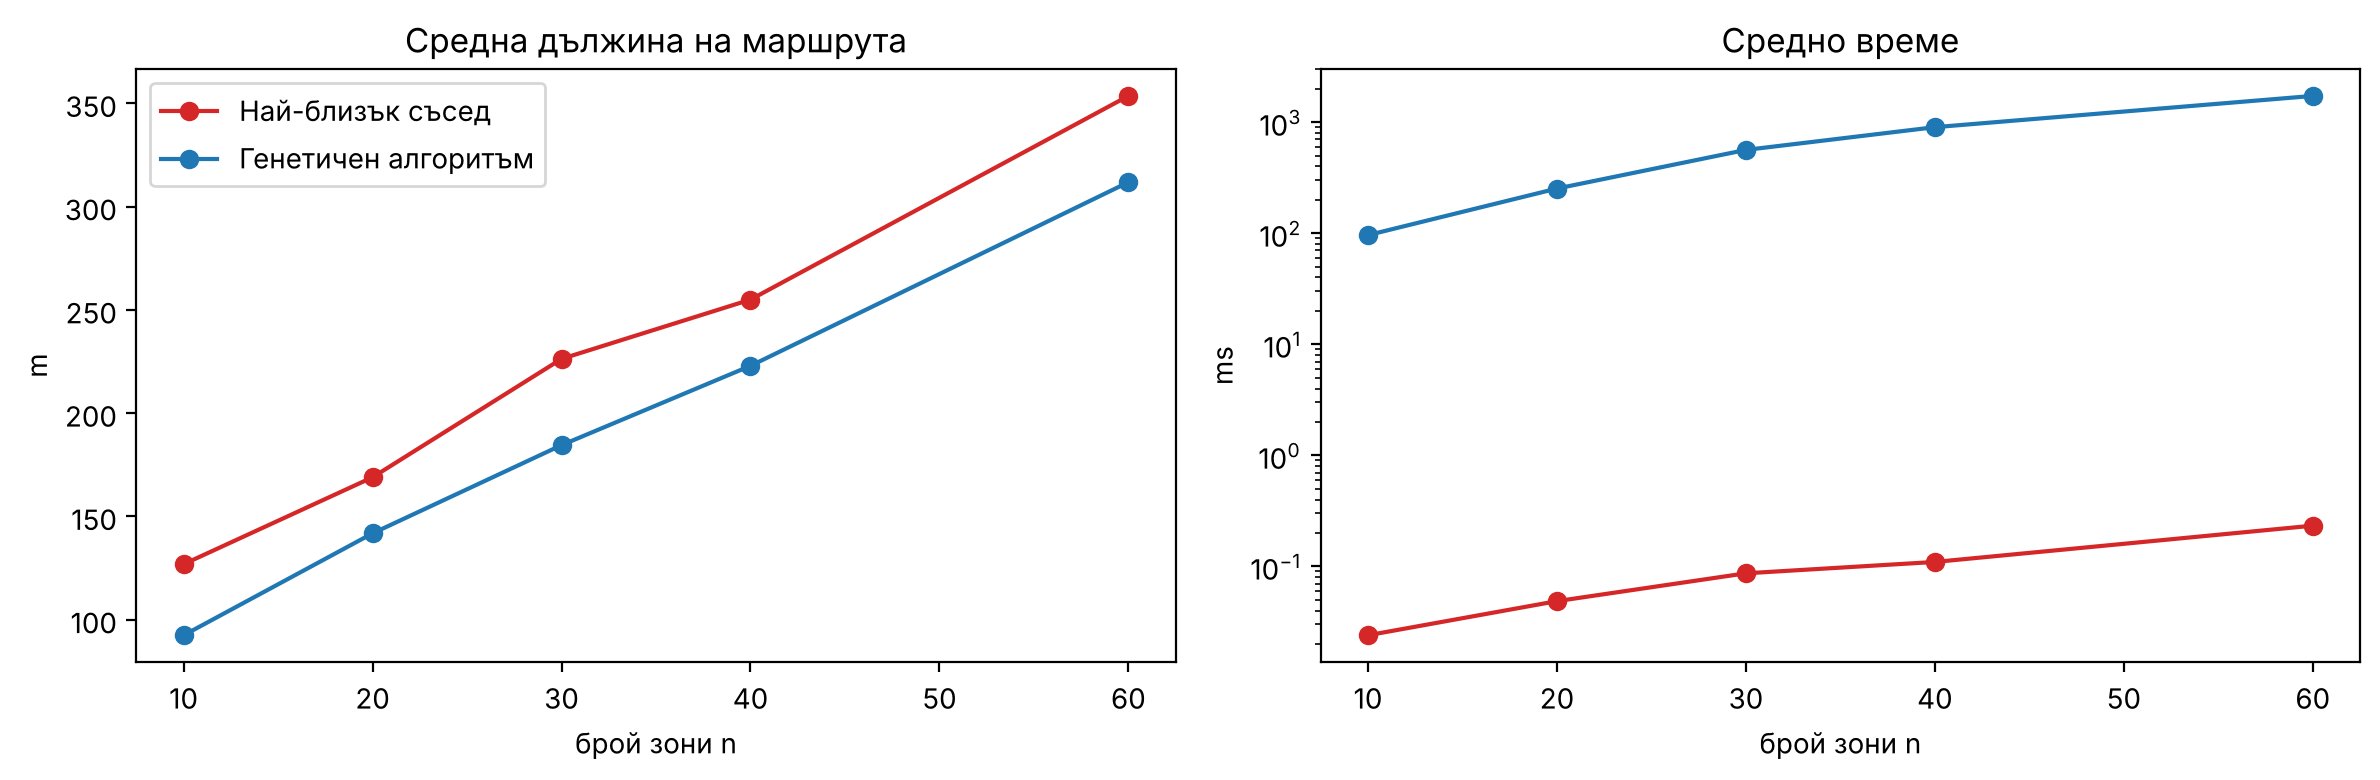

In [10]:
big_ns = [10, 20, 30, 40, 60]
res = {m: {"d": [], "t": []} for m in methods[:2]}
impr = []
for n in big_ns:
    d_nn, d_ga, t_nn, t_ga = [], [], [], []
    for seed in range(5):
        prob = random_problem(n, seed=seed, wall_w=30, wall_h=15)
        a, b = nearest_neighbor(prob), genetic_algorithm(prob, seed=seed)
        d_nn.append(a.distance); d_ga.append(b.distance); t_nn.append(a.seconds); t_ga.append(b.seconds)
    impr.append(statistics.mean((x - y) / x * 100 for x, y in zip(d_nn, d_ga)))
    res[methods[0]]["d"].append(statistics.mean(d_nn)); res[methods[1]]["d"].append(statistics.mean(d_ga))
    res[methods[0]]["t"].append(statistics.mean(t_nn) * 1000); res[methods[1]]["t"].append(statistics.mean(t_ga) * 1000)
    print(f"n = {n:>2}: НС {statistics.mean(d_nn):7.1f} m ({statistics.mean(t_nn)*1000:6.2f} ms) | "
          f"ГА {statistics.mean(d_ga):7.1f} m ({statistics.mean(t_ga)*1000:7.0f} ms) | ГА по-къс с {impr[-1]:.1f} %")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for m, c in zip(methods[:2], ["tab:red", "tab:blue"]):
    ax[0].plot(big_ns, res[m]["d"], "o-", color=c, label=m)
    ax[1].plot(big_ns, res[m]["t"], "o-", color=c, label=m)
ax[0].set_title("Средна дължина на маршрута"); ax[0].set_ylabel("m"); ax[0].set_xlabel("брой зони n"); ax[0].legend()
ax[1].set_title("Средно време"); ax[1].set_yscale("log"); ax[1].set_ylabel("ms"); ax[1].set_xlabel("брой зони n")
plt.tight_layout(); plt.savefig("results/emp_large.png", dpi=120); plt.show()

## 8. Сходимост на генетичния алгоритъм
Най-доброто разстояние по поколения при 5 различни начални зърна (seed). Хоризонталната линия е решението на най-близкия съсед.

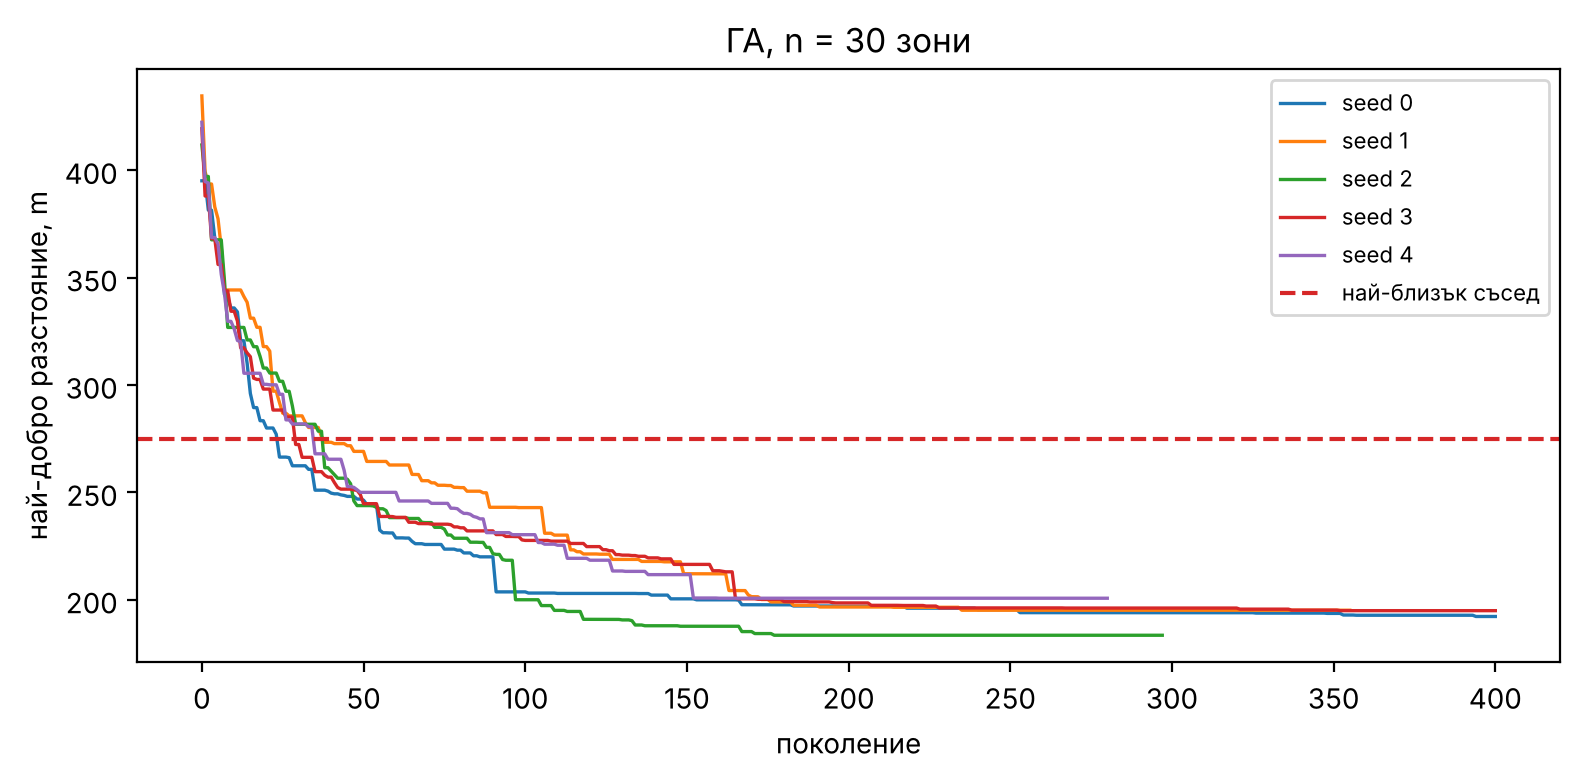

In [11]:
prob = random_problem(30, seed=3)
nn = nearest_neighbor(prob)
plt.figure(figsize=(8, 4))
for s in range(5):
    plt.plot(genetic_algorithm(prob, seed=s).history, lw=1.2, label=f"seed {s}")
plt.axhline(nn.distance, color="tab:red", ls="--", label="най-близък съсед")
plt.xlabel("поколение"); plt.ylabel("най-добро разстояние, m"); plt.title("ГА, n = 30 зони"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("results/emp_ga_convergence.png", dpi=120); plt.show()

## 9. Чувствителност към батерията
По-слаба батерия → повече рейсове → повече празни полети до базата. Как реагират двата метода?

In [12]:
factors = [1.0, 1.25, 1.5, 2.0, 3.0, 5.0]
print(f"{'батерия x':>9} | {'рейсове НС':>10} | {'рейсове ГА':>10} | {'НС, m':>8} | {'ГА, m':>8} | {'ГА по-добър с':>13}")
for f in factors:
    a_d, b_d, a_t, b_t = [], [], [], []
    for seed in range(5):
        prob = random_problem(20, seed=seed, battery_factor=f)
        a, b = nearest_neighbor(prob), genetic_algorithm(prob, seed=seed)
        a_d.append(a.distance); b_d.append(b.distance); a_t.append(a.n_trips); b_t.append(b.n_trips)
    m_a, m_b = statistics.mean(a_d), statistics.mean(b_d)
    print(f"{f:>9} | {statistics.mean(a_t):10.1f} | {statistics.mean(b_t):10.1f} | {m_a:8.1f} | {m_b:8.1f} | {(m_a - m_b) / m_a * 100:12.1f} %")

батерия x | рейсове НС | рейсове ГА |    НС, m |    ГА, m | ГА по-добър с


      1.0 |        8.2 |        7.8 |    427.6 |    375.2 |         12.3 %


     1.25 |        4.2 |        4.0 |    236.6 |    199.7 |         15.6 %


      1.5 |        3.0 |        3.0 |    187.0 |    154.1 |         17.6 %


      2.0 |        2.0 |        2.0 |    142.2 |    116.7 |         17.9 %


      3.0 |        1.0 |        1.0 |     96.8 |     90.1 |          6.9 %


      5.0 |        1.0 |        1.0 |     96.8 |     88.5 |          8.5 %


## 10. Върху зоните от конвейера (карта → АСД → ЕМП)

Открити зони с пукнатини: 8
   1. площ   9 плочки | редове 16-19, колони 5-11
   2. площ   6 плочки | редове 2-7, колони 10-15
   3. площ   6 плочки | редове 11-11, колони 17-22
   4. площ   4 плочки | редове 1-1, колони 2-5
   5. площ   4 плочки | редове 11-14, колони 28-29
   6. площ   4 плочки | редове 13-16, колони 7-10
   7. площ   4 плочки | редове 16-19, колони 21-21
   8. площ   3 плочки | редове 9-11, колони 11-13
Най-близък съсед          68.36 m, 2 рейса,      0.0 ms
    База→#1→#6→#8→#2→#3→База | База→#4→#7→#5→База
Генетичен алгоритъм       55.93 m, 2 рейса,     57.5 ms
    База→#6→#3→#5→#7→#1→База | База→#4→#2→#8→База
Точно (изчерпване)        55.93 m, 2 рейса,    246.8 ms
    База→#1→#7→#5→#3→#6→База | База→#4→#2→#8→База


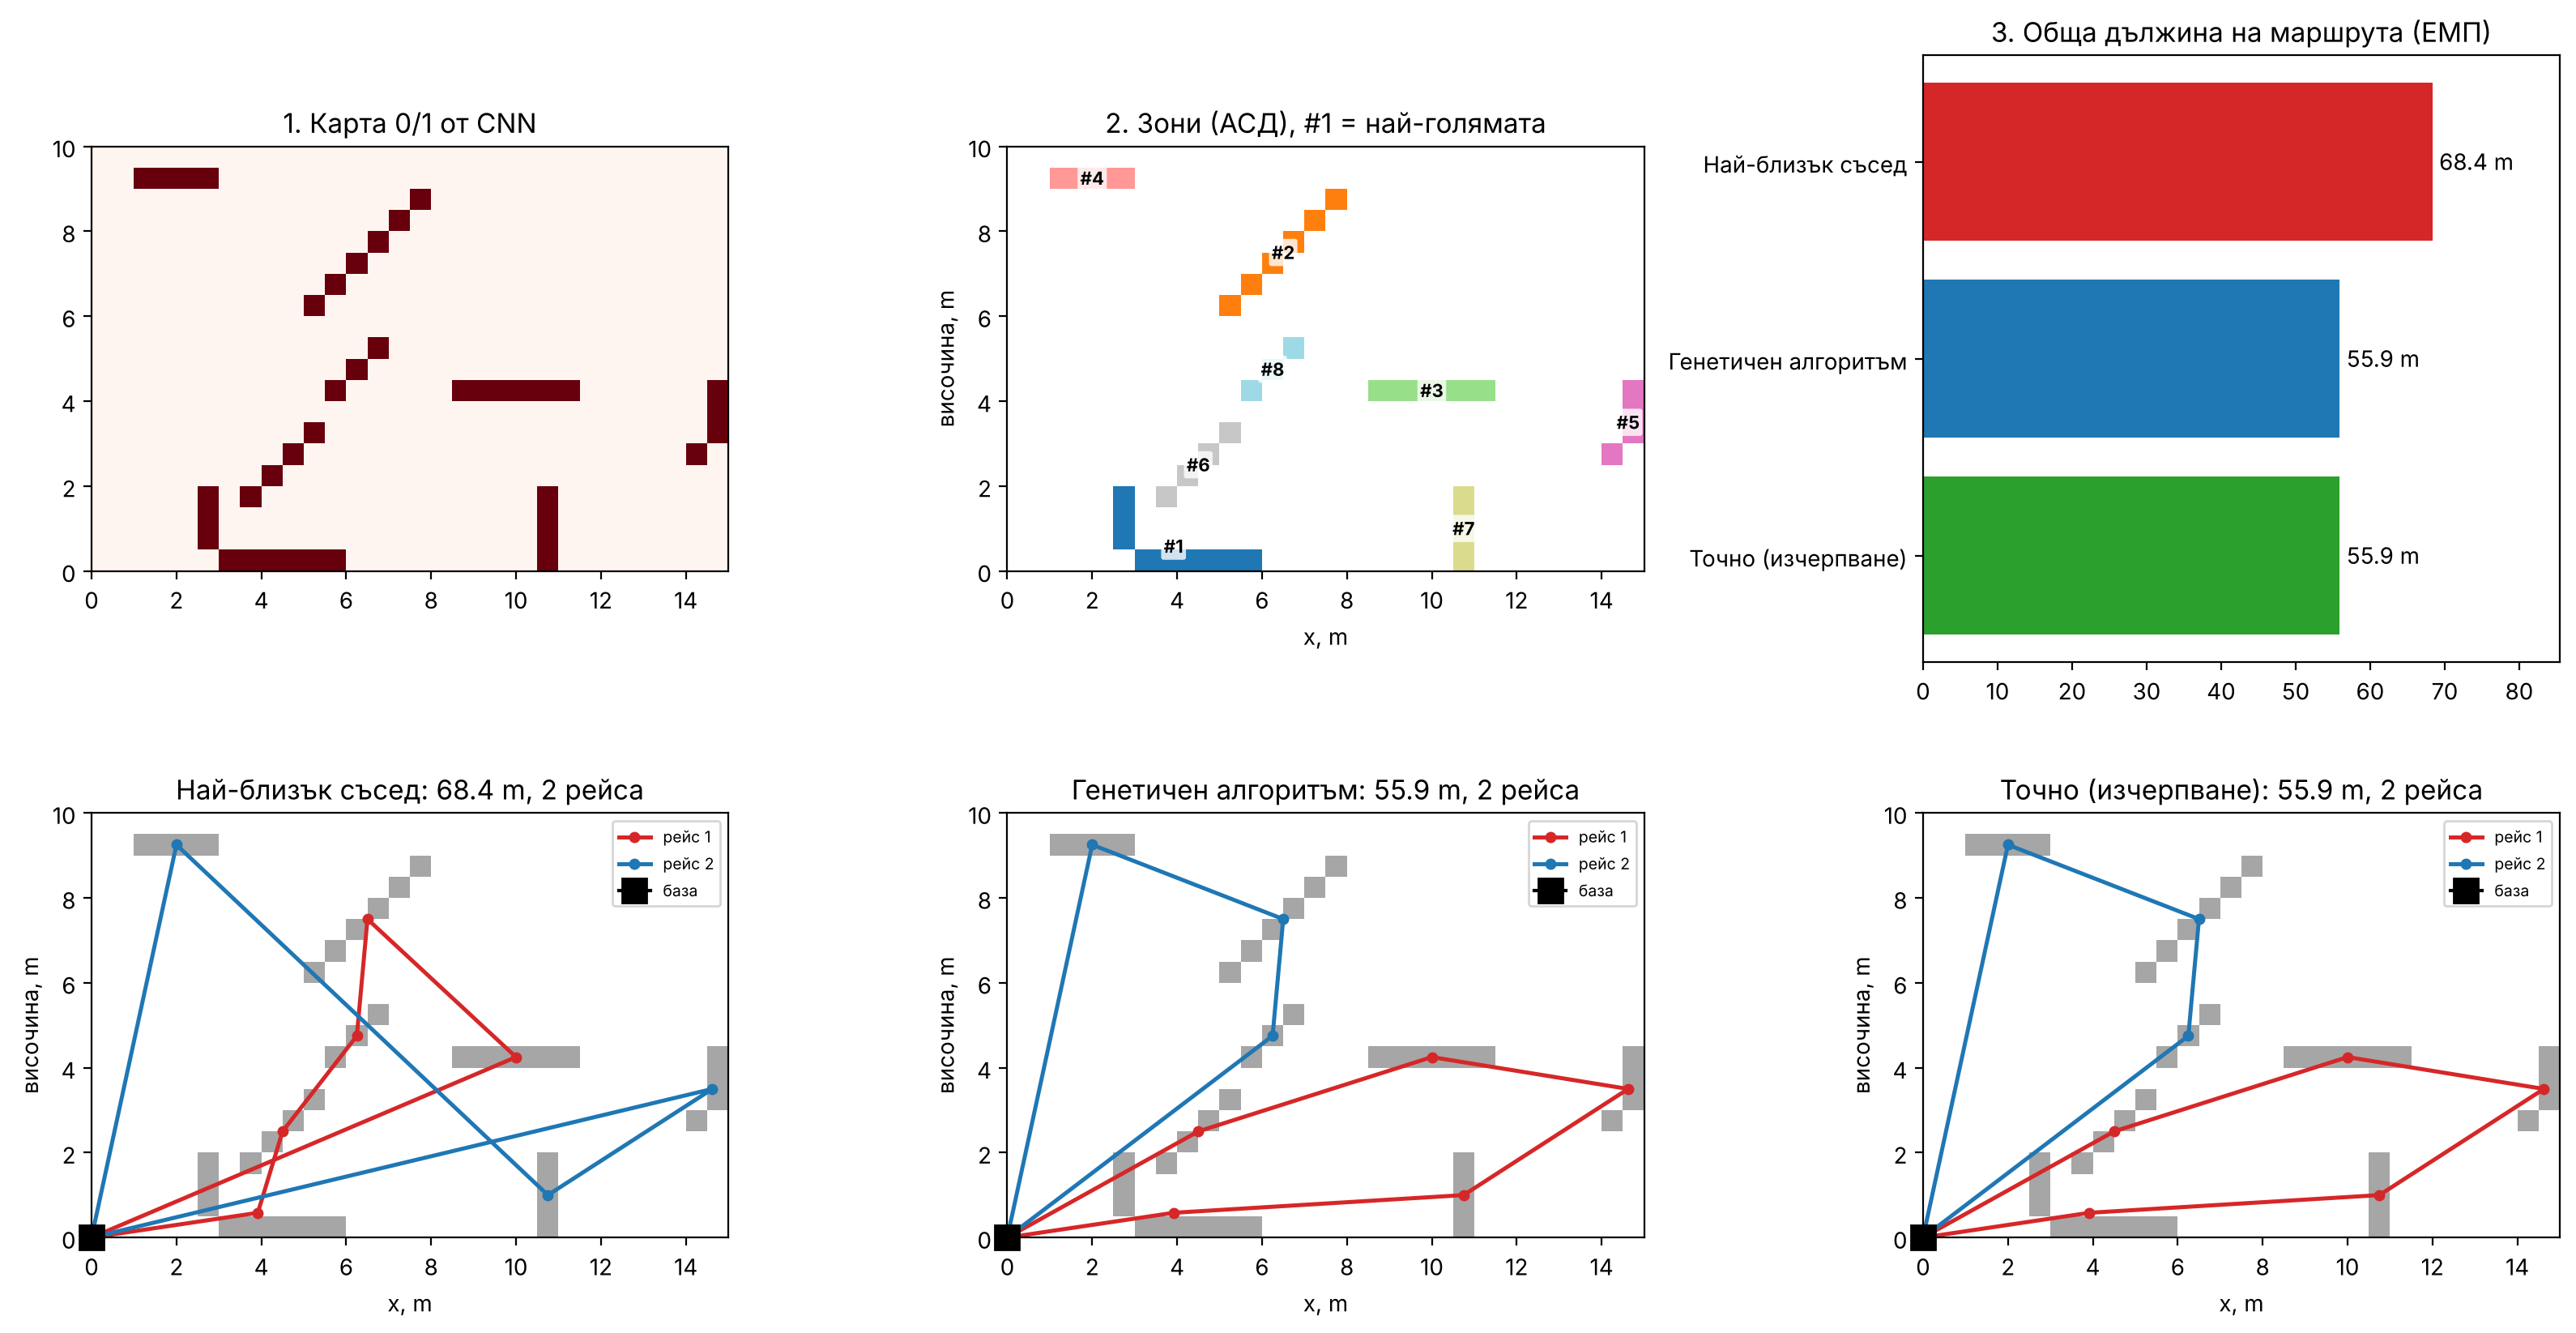

In [13]:
from src.pipeline import run_pipeline, report, InspectionConfig
from src.tiling import random_crack_mask
from src.viz import plot_pipeline

crack_map = random_crack_mask(20, 30, n_cracks=9, max_len=7, seed=2)  # при готов CNN: np.load("results/crack_map.npy")
out = run_pipeline(crack_map, InspectionConfig(battery=60))
print(report(out))
plot_pipeline(crack_map, out); plt.show()

## 11. Изводи
1. **Качество.** При малко зони (n ≤ 8) ГА намира оптимума във всички тестови задачи; най-близкият съсед е средно с 6–26 % по-лош, понякога почти двойно. При много зони (10–60) маршрутът на ГА е средно с **11–26 % по-къс** от този на най-близкия съсед.
2. **Защо най-близкият съсед греши:** алчният избор „най-близо сега“ оставя далечните зони за края на рейса, а после дронът лети на зиг-заг. Той не „вижда“ как изборът сега влияе на батерията по-късно.
3. **Време.** Най-близкият съсед: под 1 ms дори при 60 зони. ГА: 50 ms – 1.7 s. Точен метод: расте като n!, непрактичен над ~9–10 зони.
4. **Практически избор.** Планирането (под 2 s) е пренебрежимо спрямо полета (минути) – **ГА е правилният избор**, защото всеки спестен метър е спестена батерия. Най-близкият съсед остава моментален резервен план и може да се добави в началната популация на ГА (параметър `initial`).
5. **Ограничения на модела:** права линия без препятствия, постоянен разход, без вятър; огледът е пропорционален на площта, а не на формата на зоната; ГА е стохастичен – резултатът зависи от seed (виж графиката на сходимостта).